In [1]:
print("My baseline notebook is working!")

My baseline notebook is working!


In [2]:
%pip install numpy


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import numpy as np

QUICK = True
DATA_DIR = Path("deer_horse_data")

for name in ["train", "validation", "test"]:
    with np.load(DATA_DIR / f"{name}.npz") as data:
        images = data["images"]
        labels = data["labels"]

        print(
            f"{name}: shape={images.shape}, "
            f"deer={np.sum(labels == 0)}, "
            f"horse={np.sum(labels == 1)}"
        )

train: shape=(4400, 32, 32, 3), deer=4000, horse=400
validation: shape=(2000, 32, 32, 3), deer=1000, horse=1000
test: shape=(2000, 32, 32, 3), deer=1000, horse=1000


In [4]:
# Load the arrays and keep them available for later cells.
with np.load(DATA_DIR / "train.npz", allow_pickle=False) as data:
    train_images = data["images"]
    train_labels = data["labels"]
    train_indices = data["original_indices"]

with np.load(DATA_DIR / "validation.npz", allow_pickle=False) as data:
    val_images = data["images"]
    val_labels = data["labels"]
    val_indices = data["original_indices"]

# Check whether any original image index appears in both splits.
overlap = np.intersect1d(train_indices, val_indices)

print("Shared training/validation indices:", len(overlap))

assert len(overlap) == 0, "Training and validation overlap!"

# Check that neither split repeats a source image.
assert len(np.unique(train_indices)) == len(train_indices)
assert len(np.unique(val_indices)) == len(val_indices)

print("PASS: no shared source indices or repeated indices within either split.")

Shared training/validation indices: 0
PASS: no shared source indices or repeated indices within either split.


In [5]:
%pip install matplotlib


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


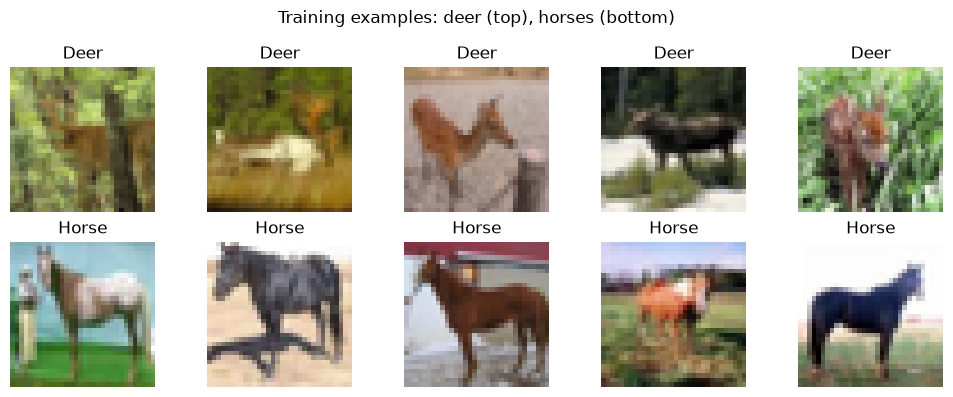

In [6]:
import matplotlib.pyplot as plt

class_names = ["Deer", "Horse"]
rng = np.random.default_rng(2026)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for label in [0, 1]:
    # Select five training images from this class.
    candidates = np.flatnonzero(train_labels == label)
    selected = rng.choice(candidates, size=5, replace=False)

    for column, index in enumerate(selected):
        axes[label, column].imshow(train_images[index])
        axes[label, column].set_title(class_names[label])
        axes[label, column].axis("off")

plt.suptitle("Training examples: deer (top), horses (bottom)")
plt.tight_layout()
plt.show()

In [7]:
%pip install torch scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Training device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.15.0+cu132
Training device: cpu


In [9]:
def make_dataset(images, labels):
    # Convert NumPy arrays into PyTorch tensors.
    # Rearrange image dimensions and scale pixels from 0–255 to 0–1.
    x = (
        torch.from_numpy(images)
        .permute(0, 3, 1, 2)
        .contiguous()
        .float()
        / 255.0
    )

    # Cross-Entropy expects integer class labels of type int64.
    y = torch.from_numpy(labels).long()

    return TensorDataset(x, y)


train_dataset = make_dataset(train_images, train_labels)
val_dataset = make_dataset(val_images, val_labels)


def make_loaders(seed, batch_size=64):
    # A fresh generator makes training-data shuffling reproducible.
    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
        num_workers=0,
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

    return train_loader, val_loader


# Preview one batch. Recreate the loaders before each training run.
preview_loader, _ = make_loaders(seed=42)
batch_images, batch_labels = next(iter(preview_loader))

print("Image batch shape:", batch_images.shape)
print("Label batch shape:", batch_labels.shape)
print("Image type:", batch_images.dtype)
print("Label type:", batch_labels.dtype)
print("Pixel range:", batch_images.min().item(), batch_images.max().item())

Image batch shape: torch.Size([64, 3, 32, 32])
Label batch shape: torch.Size([64])
Image type: torch.float32
Label type: torch.int64
Pixel range: 0.0 1.0


In [10]:
class DeerHorseCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


torch.manual_seed(42)
model = DeerHorseCNN().to(device)
model.eval()

with torch.no_grad():
    outputs = model(batch_images.to(device))

parameter_count = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Output shape:", outputs.shape)
print("Trainable parameters:", parameter_count)

assert outputs.shape == (batch_images.shape[0], 2)
assert torch.isfinite(outputs).all()

Output shape: torch.Size([64, 2])
Trainable parameters: 544066


In [11]:
class_counts = np.bincount(train_labels, minlength=2)
class_weights = len(train_labels) / (2.0 * class_counts)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device,
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

model.eval()

with torch.no_grad():
    logits = model(batch_images.to(device))
    loss = criterion(logits, batch_labels.to(device))

print("Class counts:", class_counts)
print("Class weights:", class_weights.cpu().numpy())
print("Initial batch loss:", loss.item())

assert torch.isfinite(loss)

Class counts: [4000  400]
Class weights: [0.55 5.5 ]
Initial batch loss: 0.6915404796600342


In [12]:
import time
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
)


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_weight = 0.0
    all_labels = []
    all_predictions = []

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss detected.")

            if training:
                loss.backward()
                optimizer.step()

            batch_weight = criterion.weight[labels].sum().item()
            total_loss += loss.item() * batch_weight
            total_weight += batch_weight

            predictions = logits.argmax(dim=1)
            all_labels.append(labels.detach().cpu().numpy())
            all_predictions.append(predictions.detach().cpu().numpy())

    y_true = np.concatenate(all_labels)
    y_pred = np.concatenate(all_predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="binary",
        pos_label=1,
        zero_division=0,
    )

    return {
        "loss": total_loss / total_weight,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "horse_precision": precision,
        "horse_recall": recall,
        "horse_f1": f1,
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=[0, 1]),
    }

In [13]:
torch.manual_seed(42)
np.random.seed(42)

pilot_model = DeerHorseCNN().to(device)
pilot_optimizer = torch.optim.Adam(pilot_model.parameters(), lr=0.001)
pilot_train_loader, pilot_val_loader = make_loaders(seed=42)

start_time = time.perf_counter()

pilot_train = run_epoch(
    pilot_model, pilot_train_loader, criterion, pilot_optimizer
)

pilot_val = run_epoch(
    pilot_model, pilot_val_loader, criterion
)

elapsed = time.perf_counter() - start_time

print(f"Training loss: {pilot_train['loss']:.4f}")
print(f"Validation loss: {pilot_val['loss']:.4f}")
print(f"Validation accuracy: {pilot_val['accuracy']:.4f}")
print(f"Horse precision: {pilot_val['horse_precision']:.4f}")
print(f"Horse recall: {pilot_val['horse_recall']:.4f}")
print(f"Horse F1: {pilot_val['horse_f1']:.4f}")
print("Validation confusion matrix:")
print(pilot_val["confusion_matrix"])
print(f"Time for one training epoch plus validation: {elapsed:.1f} seconds")

Training loss: 0.6956
Validation loss: 0.6874
Validation accuracy: 0.6645
Horse precision: 0.6897
Horse recall: 0.5980
Horse F1: 0.6406
Validation confusion matrix:
[[731 269]
 [402 598]]
Time for one training epoch plus validation: 6.6 seconds


In [14]:
LEARNING_RATES = [0.0001, 0.001, 0.01]
TUNING_SEED = 2026
EPOCHS = 30

tuning_results = []
tuning_histories = {}

for lr in LEARNING_RATES:
    torch.manual_seed(TUNING_SEED)
    np.random.seed(TUNING_SEED)

    tuning_model = DeerHorseCNN().to(device)
    optimizer = torch.optim.Adam(tuning_model.parameters(), lr=lr)
    train_loader, val_loader = make_loaders(seed=TUNING_SEED)

    history = []
    start_time = time.perf_counter()

    print(f"\nLearning rate: {lr}")

    for epoch in range(1, EPOCHS + 1):
        train_metrics = run_epoch(
            tuning_model, train_loader, criterion, optimizer
        )
        val_metrics = run_epoch(
            tuning_model, val_loader, criterion
        )

        history.append({
            "epoch": epoch,
            "train_loss": float(train_metrics["loss"]),
            "val_loss": float(val_metrics["loss"]),
            "val_horse_f1": float(val_metrics["horse_f1"]),
            "val_horse_precision": float(val_metrics["horse_precision"]),
            "val_horse_recall": float(val_metrics["horse_recall"]),
        })

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:02d}/{EPOCHS} | "
                f"Train loss: {train_metrics['loss']:.4f} | "
                f"Val loss: {val_metrics['loss']:.4f} | "
                f"Horse F1: {val_metrics['horse_f1']:.4f}"
            )

    tuning_histories[str(lr)] = history
    tuning_results.append({
        "learning_rate": lr,
        "final_val_horse_f1": float(val_metrics["horse_f1"]),
        "seconds": time.perf_counter() - start_time,
    })

best_result = max(
    tuning_results,
    key=lambda result: (
        result["final_val_horse_f1"],
        -result["learning_rate"],
    ),
)

best_lr = best_result["learning_rate"]

print("\nTuning results:")
for result in tuning_results:
    print(result)

print("\nSelected learning rate:", best_lr)


Learning rate: 0.0001
Epoch 01/30 | Train loss: 0.6762 | Val loss: 0.6625 | Horse F1: 0.6351
Epoch 05/30 | Train loss: 0.5155 | Val loss: 0.5811 | Horse F1: 0.7252
Epoch 10/30 | Train loss: 0.4524 | Val loss: 0.3219 | Horse F1: 0.7710
Epoch 15/30 | Train loss: 0.3941 | Val loss: 0.3938 | Horse F1: 0.7867
Epoch 20/30 | Train loss: 0.3582 | Val loss: 0.5300 | Horse F1: 0.7758
Epoch 25/30 | Train loss: 0.3154 | Val loss: 0.4857 | Horse F1: 0.7901
Epoch 30/30 | Train loss: 0.2812 | Val loss: 0.5280 | Horse F1: 0.7879

Learning rate: 0.001
Epoch 01/30 | Train loss: 0.6763 | Val loss: 0.6050 | Horse F1: 0.7148
Epoch 05/30 | Train loss: 0.4158 | Val loss: 0.4964 | Horse F1: 0.7855
Epoch 10/30 | Train loss: 0.2212 | Val loss: 0.6989 | Horse F1: 0.7808
Epoch 15/30 | Train loss: 0.1272 | Val loss: 0.8970 | Horse F1: 0.7878
Epoch 20/30 | Train loss: 0.0492 | Val loss: 1.7953 | Horse F1: 0.7205
Epoch 25/30 | Train loss: 0.0054 | Val loss: 2.6222 | Horse F1: 0.7093
Epoch 30/30 | Train loss: 0.0018

In [15]:
import json

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

tuning_record = {
    "tuning_seed": TUNING_SEED,
    "epochs": EPOCHS,
    "batch_size": 64,
    "optimizer": "Adam",
    "learning_rates": LEARNING_RATES,
    "selection_metric": "validation_horse_f1",
    "selection_epoch": EPOCHS,
    "tie_break": "smaller_learning_rate",
    "selected_learning_rate": best_lr,
    "class_weights": class_weights.detach().cpu().tolist(),
    "results": tuning_results,
    "histories": tuning_histories,
}

output_path = RESULTS_DIR / "nb1_tuning.json"

with output_path.open("w") as file:
    json.dump(tuning_record, file, indent=2, allow_nan=False)

print("Selected learning rate:", best_lr)
print("Saved:", output_path)

Selected learning rate: 0.0001
Saved: results/nb1_tuning.json


In [16]:
import random

SEEDS = [42, 123, 456]
CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

with (RESULTS_DIR / "nb1_tuning.json").open() as file:
    saved_tuning = json.load(file)

selected_lr = saved_tuning["selected_learning_rate"]
baseline_epochs = saved_tuning["epochs"]
baseline_batch_size = saved_tuning["batch_size"]


def serialise_metrics(metrics):
    return {
        key: value.tolist() if isinstance(value, np.ndarray) else float(value)
        for key, value in metrics.items()
    }


def train_baseline(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    model = DeerHorseCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=selected_lr)

    train_loader, val_loader = make_loaders(
        seed=seed,
        batch_size=baseline_batch_size,
    )

    history = []
    start_time = time.perf_counter()

    for epoch in range(1, baseline_epochs + 1):
        train_metrics = run_epoch(
            model, train_loader, criterion, optimizer
        )
        val_metrics = run_epoch(
            model, val_loader, criterion
        )

        history.append({
            "epoch": epoch,
            "train": serialise_metrics(train_metrics),
            "validation": serialise_metrics(val_metrics),
        })

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Seed {seed} | Epoch {epoch:02d}/{baseline_epochs} | "
                f"Train loss: {train_metrics['loss']:.4f} | "
                f"Val Horse F1: {val_metrics['horse_f1']:.4f}",
                flush=True,
            )

    record = {
        "seed": seed,
        "learning_rate": selected_lr,
        "epochs": baseline_epochs,
        "batch_size": baseline_batch_size,
        "optimizer": "Adam",
        "optimizer_settings": {
            "betas": [0.9, 0.999],
            "eps": 1e-8,
            "weight_decay": 0.0,
        },
        "class_weights": class_weights.detach().cpu().tolist(),
        "preprocessing": "RGB float32 divided by 255; NCHW",
        "torch_version": str(torch.__version__),
        "numpy_version": str(np.__version__),
        "device": str(device),
        "seconds": time.perf_counter() - start_time,
        "final_validation": serialise_metrics(val_metrics),
        "history": history,
    }

    checkpoint_path = CHECKPOINT_DIR / f"nb1_seed_{seed}.pt"

    torch.save(
        {
            "model_state_dict": {
                name: tensor.detach().cpu()
                for name, tensor in model.state_dict().items()
            },
            "seed": seed,
            "epochs": baseline_epochs,
            "learning_rate": selected_lr,
        },
        checkpoint_path,
    )

    record["checkpoint"] = checkpoint_path.as_posix()

    with (RESULTS_DIR / f"nb1_seed_{seed}.json").open("w") as file:
        json.dump(record, file, indent=2, allow_nan=False)

    print(f"Saved results and checkpoint for seed {seed}")
    return record

In [17]:
QUICK = True

baseline_records = []

for seed in SEEDS:
    if QUICK:
        result_path = RESULTS_DIR / f"nb1_seed_{seed}.json"

        if not result_path.exists():
            raise FileNotFoundError(
                f"Missing {result_path}. Run with QUICK=False first."
            )

        with result_path.open() as file:
            record = json.load(file)
    else:
        record = train_baseline(seed)

    baseline_records.append(record)

scores = np.array([
    record["final_validation"]["horse_f1"]
    for record in baseline_records
])

print("\nValidation Horse F1:")
for seed, score in zip(SEEDS, scores):
    print(f"Seed {seed}: {score:.4f}")

print(f"Mean: {scores.mean():.4f}")
print(f"Sample standard deviation: {scores.std(ddof=1):.4f}")


Validation Horse F1:
Seed 42: 0.8078
Seed 123: 0.7948
Seed 456: 0.7857
Mean: 0.7961
Sample standard deviation: 0.0111


In [18]:
with np.load(DATA_DIR / "test.npz", allow_pickle=False) as data:
    test_images = data["images"]
    test_labels = data["labels"]

test_dataset = make_dataset(test_images, test_labels)

test_loader = DataLoader(
    test_dataset,
    batch_size=baseline_batch_size,
    shuffle=False,
    num_workers=0,
)

test_records = []

for seed in SEEDS:
    checkpoint = torch.load(
        CHECKPOINT_DIR / f"nb1_seed_{seed}.pt",
        map_location="cpu",
        weights_only=True,
    )

    test_model = DeerHorseCNN().to(device)
    test_model.load_state_dict(checkpoint["model_state_dict"])

    metrics = run_epoch(test_model, test_loader, criterion)

    record = {
        "seed": seed,
        "learning_rate": checkpoint["learning_rate"],
        "epochs": checkpoint["epochs"],
        "test": serialise_metrics(metrics),
    }

    test_records.append(record)

    print(
        f"Seed {seed} | "
        f"Accuracy: {metrics['accuracy']:.4f} | "
        f"Horse precision: {metrics['horse_precision']:.4f} | "
        f"Horse recall: {metrics['horse_recall']:.4f} | "
        f"Horse F1: {metrics['horse_f1']:.4f}"
    )
    print(metrics["confusion_matrix"])

metric_names = [
    "accuracy",
    "balanced_accuracy",
    "horse_precision",
    "horse_recall",
    "horse_f1",
]

test_summary = {}

print("\nTest results: mean ± sample standard deviation")

for metric in metric_names:
    values = np.array([
        record["test"][metric] for record in test_records
    ])

    test_summary[metric] = {
        "mean": float(values.mean()),
        "sample_std": float(values.std(ddof=1)),
    }

    print(
        f"{metric}: "
        f"{values.mean():.4f} ± {values.std(ddof=1):.4f}"
    )

with (RESULTS_DIR / "nb1_test_results.json").open("w") as file:
    json.dump(
        {"runs": test_records, "summary": test_summary},
        file,
        indent=2,
        allow_nan=False,
    )

print("\nSaved: results/nb1_test_results.json")

Seed 42 | Accuracy: 0.8225 | Horse precision: 0.8413 | Horse recall: 0.7950 | Horse F1: 0.8175
[[850 150]
 [205 795]]
Seed 123 | Accuracy: 0.8240 | Horse precision: 0.8403 | Horse recall: 0.8000 | Horse F1: 0.8197
[[848 152]
 [200 800]]
Seed 456 | Accuracy: 0.8155 | Horse precision: 0.8448 | Horse recall: 0.7730 | Horse F1: 0.8073
[[858 142]
 [227 773]]

Test results: mean ± sample standard deviation
accuracy: 0.8207 ± 0.0045
balanced_accuracy: 0.8207 ± 0.0045
horse_precision: 0.8421 ± 0.0024
horse_recall: 0.7893 ± 0.0144
horse_f1: 0.8148 ± 0.0066

Saved: results/nb1_test_results.json


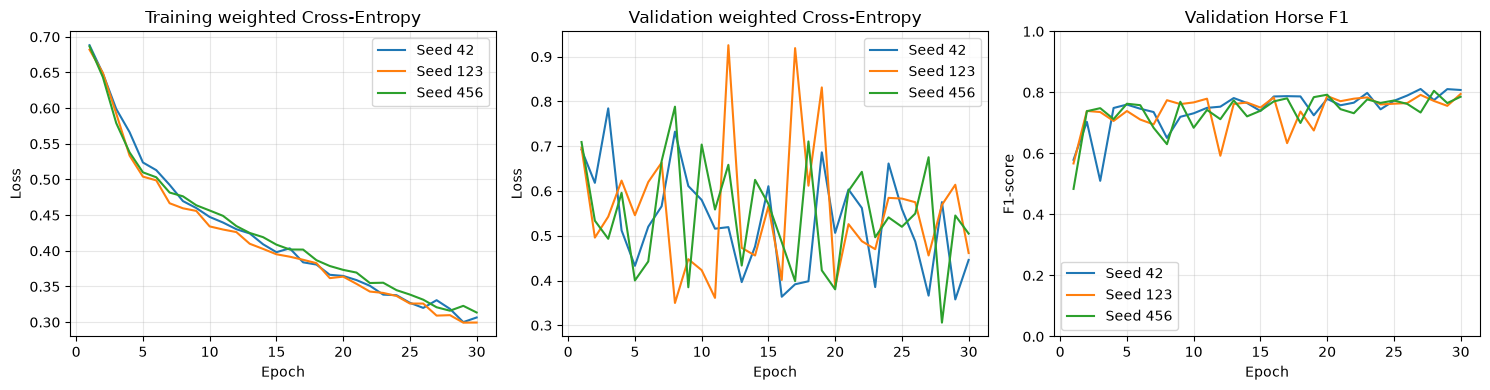

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for record in baseline_records:
    seed = record["seed"]
    history = record["history"]

    epochs = [entry["epoch"] for entry in history]
    train_losses = [entry["train"]["loss"] for entry in history]
    val_losses = [entry["validation"]["loss"] for entry in history]
    val_f1 = [entry["validation"]["horse_f1"] for entry in history]

    axes[0].plot(epochs, train_losses, label=f"Seed {seed}")
    axes[1].plot(epochs, val_losses, label=f"Seed {seed}")
    axes[2].plot(epochs, val_f1, label=f"Seed {seed}")

axes[0].set_title("Training weighted Cross-Entropy")
axes[1].set_title("Validation weighted Cross-Entropy")
axes[2].set_title("Validation Horse F1")

axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Loss")
axes[2].set_ylabel("F1-score")
axes[2].set_ylim(0, 1)

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "nb1_learning_curves.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()